<a href="https://colab.research.google.com/github/Mayuri0320/Datax504-Mayuri/blob/main/Final_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
from pathlib import Path
import requests
import json

DATA_DIR = Path("bc5cdr_dataset")
DATA_DIR.mkdir(parents=True, exist_ok=True)

BASE_URL = "https://huggingface.co/datasets/tner/bc5cdr/resolve/main/dataset/"
SOURCE_FILES = ["train.json", "valid.json", "test.json", "label.json"]

for filename in SOURCE_FILES:
    target = DATA_DIR / filename
    response = requests.get(BASE_URL + filename, timeout=120)
    response.raise_for_status()
    target.write_bytes(response.content)
    print(f"Downloaded {filename}: {target.stat().st_size:,} bytes")


Downloaded train.json: 1,420,628 bytes
Downloaded valid.json: 1,416,330 bytes
Downloaded test.json: 1,507,322 bytes
Downloaded label.json: 74 bytes


In [5]:
def read_json_or_jsonl(path):
    text = path.read_text(encoding="utf-8")
    try:
        obj = json.loads(text)
        if isinstance(obj, list):
            return obj
        if isinstance(obj, dict):
            if "tokens" in obj and "tags" in obj:
                return [obj]
            # Some JSON formats store records under keys.
            return list(obj.values())
    except json.JSONDecodeError:
        pass
    return [json.loads(line) for line in text.splitlines() if line.strip()]

with open(DATA_DIR / "label.json", encoding="utf-8") as f:
    label_data = json.load(f)

if isinstance(label_data, dict):
    label2id_source = {str(k): int(v) for k, v in label_data.items()}
    id2label_source = {v: k for k, v in label2id_source.items()}
elif isinstance(label_data, list):
    id2label_source = {i: str(label) for i, label in enumerate(label_data)}
    label2id_source = {v: k for k, v in id2label_source.items()}
else:
    raise ValueError(f"Unexpected label.json structure: {type(label_data)}")

def normalize_tag(tag):
    if isinstance(tag, int):
        if tag not in id2label_source:
            raise ValueError(f"Unknown label ID: {tag}")
        return id2label_source[tag]
    tag = str(tag)
    if tag not in label2id_source:
        raise ValueError(f"Unknown label: {tag}")
    return tag

def normalize_records(records, split_name):
    normalized = []
    for i, record in enumerate(records):
        if "tokens" not in record or "tags" not in record:
            raise ValueError(f"{split_name} record {i} lacks tokens/tags. Keys: {list(record)}")
        tokens, tags = record["tokens"], record["tags"]
        if len(tokens) != len(tags):
            raise ValueError(f"{split_name} record {i}: {len(tokens)} tokens but {len(tags)} tags")
        normalized.append({
            "tokens": [str(token) for token in tokens],
            "tags": [normalize_tag(tag) for tag in tags],
        })
    return normalized

train_source = normalize_records(read_json_or_jsonl(DATA_DIR / "train.json"), "train")
valid_source = normalize_records(read_json_or_jsonl(DATA_DIR / "valid.json"), "valid")
test_source = normalize_records(read_json_or_jsonl(DATA_DIR / "test.json"), "test")

print("Label mapping:", label2id_source)
print(f"Train sentences: {len(train_source):,}")
print(f"Validation sentences: {len(valid_source):,}")
print(f"Test sentences: {len(test_source):,}")
print("Example:", list(zip(train_source[0]["tokens"], train_source[0]["tags"]))[:20])

def write_conll(records, filename):
    output = DATA_DIR / filename
    with open(output, "w", encoding="utf-8") as f:
        for record in records:
            for token, tag in zip(record["tokens"], record["tags"]):
                token = token.replace("\t", "_").replace("\n", "_")
                f.write(f"{token}\t{tag}\n")
            f.write("\n")
    print(f"Created {output}: {output.stat().st_size:,} bytes")

write_conll(train_source, "train.conll")
write_conll(valid_source, "valid.conll")
write_conll(test_source, "test.conll")

for filename in ["train.conll", "valid.conll", "test.conll"]:
    print(f"\n--- {filename} ---")
    print((DATA_DIR / filename).read_text(encoding="utf-8")[:350])


Label mapping: {'O': 0, 'B-Chemical': 1, 'B-Disease': 2, 'I-Disease': 3, 'I-Chemical': 4}
Train sentences: 5,228
Validation sentences: 5,330
Test sentences: 5,865
Example: [('Naloxone', 'B-Chemical'), ('reverses', 'O'), ('the', 'O'), ('antihypertensive', 'O'), ('effect', 'O'), ('of', 'O'), ('clonidine', 'B-Chemical'), ('.', 'O')]
Created bc5cdr_dataset/train.conll: 974,260 bytes
Created bc5cdr_dataset/valid.conll: 969,443 bytes
Created bc5cdr_dataset/test.conll: 1,019,828 bytes

--- train.conll ---
Naloxone	B-Chemical
reverses	O
the	O
antihypertensive	O
effect	O
of	O
clonidine	B-Chemical
.	O

In	O
unanesthetized	O
,	O
spontaneously	O
hypertensive	B-Disease
rats	O
the	O
decrease	O
in	O
blood	O
pressure	O
and	O
heart	O
rate	O
produced	O
by	O
intravenous	O
clonidine	B-Chemical
,	O
5	O
to	O
20	O
micrograms	O
/	O
kg	O
,	O
was	O
inhibited	O
or	O
re

--- valid.conll ---
Tricuspid	B-Disease
valve	I-Disease
regurgitation	I-Disease
and	O
lithium	B-Chemical
carbonate	I-Chemical
toxicity	B-Disease

In [6]:
import os
os.environ["KERAS_BACKEND"] = "torch"

import json, random, copy, math
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import torch
import keras
from keras import layers
from tqdm.auto import tqdm
from transformers import AutoTokenizer, AutoModelForTokenClassification
from torch.utils.data import Dataset, DataLoader

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DATA_DIR = Path("bc5cdr_dataset")
assert (DATA_DIR / "train.conll").exists(), "train.conll not found. Keep the existing bc5cdr_dataset folder in this notebook's working directory."
assert (DATA_DIR / "valid.conll").exists(), "valid.conll not found."
assert (DATA_DIR / "test.conll").exists(), "test.conll not found."

print("Keras:", keras.__version__)
print("Keras backend:", keras.backend.backend())
print("PyTorch:", torch.__version__)
print("Transformers:", __import__("transformers").__version__)
print("Device:", "cuda" if torch.cuda.is_available() else "cpu")


Keras: 3.13.2
Keras backend: torch
PyTorch: 2.11.0+cu130
Transformers: 5.18.0
Device: cuda


In [7]:
def read_conll(filename):
    sentences = []
    tokens, tags = [], []
    with open(DATA_DIR / filename, encoding="utf-8") as f:
        for raw_line in f:
            line = raw_line.rstrip("\n")
            if not line.strip():
                if tokens:
                    sentences.append({"tokens": tokens, "tags": tags})
                    tokens, tags = [], []
                continue
            parts = line.split("\t")
            if len(parts) != 2:
                raise ValueError(f"Invalid CoNLL line in {filename}: {line!r}")
            token, tag = parts
            tokens.append(token)
            tags.append(tag)
    if tokens:
        sentences.append({"tokens": tokens, "tags": tags})
    return sentences

train_data = read_conll("train.conll")
valid_data = read_conll("valid.conll")
test_data = read_conll("test.conll")

print(f"Train: {len(train_data):,} sentences")
print(f"Validation: {len(valid_data):,} sentences")
print(f"Test: {len(test_data):,} sentences")
print("Example:", list(zip(train_data[0]["tokens"], train_data[0]["tags"]))[:20])


Train: 5,228 sentences
Validation: 5,330 sentences
Test: 5,865 sentences
Example: [('Naloxone', 'B-Chemical'), ('reverses', 'O'), ('the', 'O'), ('antihypertensive', 'O'), ('effect', 'O'), ('of', 'O'), ('clonidine', 'B-Chemical'), ('.', 'O')]


In [8]:
with open(DATA_DIR / "label.json", encoding="utf-8") as f:
    raw_label_map = json.load(f)

if isinstance(raw_label_map, dict):

    LABELS = [label for label, idx in sorted(raw_label_map.items(), key=lambda x: int(x[1]))]
else:
    LABELS = list(raw_label_map)


observed = {tag for split in (train_data, valid_data, test_data) for row in split for tag in row["tags"]}
LABELS = list(dict.fromkeys(LABELS + sorted(observed - set(LABELS))))
LABEL2ID = {label: i for i, label in enumerate(LABELS)}
ID2LABEL = {i: label for label, i in LABEL2ID.items()}
NUM_LABELS = len(LABELS)

assert set(observed).issubset(set(LABELS))
print("Labels:", LABEL2ID)

def extract_entities(tags):
    entities = set()
    active_type, start = None, None
    def close(end):
        nonlocal active_type, start
        if active_type is not None:
            entities.add((active_type, start, end))
        active_type, start = None, None

    for i, tag in enumerate(list(tags) + ["O"]):
        if tag == "O" or "-" not in tag:
            close(i)
            continue
        prefix, entity_type = tag.split("-", 1)
        if prefix == "B":
            close(i)
            active_type, start = entity_type, i
        elif prefix == "I":
            if active_type != entity_type:
                close(i)
                active_type, start = entity_type, i
        else:
            close(i)
    return entities

def entity_metrics(gold_sequences, pred_sequences, entity_type=None):
    gold_set, pred_set = set(), set()
    for s, tags in enumerate(gold_sequences):
        for typ, start, end in extract_entities(tags):
            if entity_type is None or typ == entity_type:
                gold_set.add((s, typ, start, end))
    for s, tags in enumerate(pred_sequences):
        for typ, start, end in extract_entities(tags):
            if entity_type is None or typ == entity_type:
                pred_set.add((s, typ, start, end))
    correct = len(gold_set & pred_set)
    precision = correct / len(pred_set) if pred_set else 0.0
    recall = correct / len(gold_set) if gold_set else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return {"precision": precision, "recall": recall, "f1": f1,
            "correct": correct, "gold": len(gold_set), "predicted": len(pred_set)}

def print_report(gold, pred):
    for name, typ in [("Overall", None), ("Chemical", "Chemical"), ("Disease", "Disease")]:
        m = entity_metrics(gold, pred, typ)
        print(f"{name:10s} P={m['precision']:.4f} R={m['recall']:.4f} "
              f"F1={m['f1']:.4f} | correct={m['correct']}/{m['gold']} gold entities")


Labels: {'O': 0, 'B-Chemical': 1, 'B-Disease': 2, 'I-Disease': 3, 'I-Chemical': 4}


In [9]:

PAD, UNK = "<PAD>", "<UNK>"
counts = Counter(tok.lower() for row in train_data for tok in row["tokens"])
word2id = {PAD: 0, UNK: 1}
for word, _ in counts.most_common():
    if word not in word2id:
        word2id[word] = len(word2id)

PAD_ID, UNK_ID = word2id[PAD], word2id[UNK]
MAX_WORDS = 256

def encode_split(records):
    X, Y = [], []
    for row in records:
        tokens = row["tokens"][:MAX_WORDS]
        tags = row["tags"][:MAX_WORDS]
        X.append([word2id.get(t.lower(), UNK_ID) for t in tokens])
        Y.append([LABEL2ID[t] for t in tags])
    return X, Y

X_train, y_train = encode_split(train_data)
X_valid, y_valid = encode_split(valid_data)
X_test, y_test = encode_split(test_data)

def pad_xy(X, Y, max_len=MAX_WORDS):
    xp = np.full((len(X), max_len), PAD_ID, dtype=np.int32)
    yp = np.full((len(Y), max_len), -100, dtype=np.int32)
    for i, (x, y) in enumerate(zip(X, Y)):
        n = min(len(x), max_len)
        xp[i, :n] = x[:n]
        yp[i, :n] = y[:n]
    return xp, yp

xtr, ytr = pad_xy(X_train, y_train)
xva, yva = pad_xy(X_valid, y_valid)
xte, yte = pad_xy(X_test, y_test)


ytr_safe = np.where(ytr == -100, 0, ytr)
yva_safe = np.where(yva == -100, 0, yva)
yte_safe = np.where(yte == -100, 0, yte)
train_weight = (ytr != -100).astype("float32")
valid_weight = (yva != -100).astype("float32")
test_weight = (yte != -100).astype("float32")

bilstm = keras.Sequential([
    layers.Input(shape=(MAX_WORDS,), dtype="int32"),
    layers.Embedding(len(word2id), 128, mask_zero=True),
    layers.Bidirectional(layers.LSTM(64, return_sequences=True)),
    layers.Dropout(0.25),
    layers.Dense(NUM_LABELS, activation="softmax"),
], name="bilstm_baseline")

bilstm.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    weighted_metrics=[keras.metrics.SparseCategoricalAccuracy(name="token_accuracy")],
)
bilstm.summary()


Model: "bilstm_baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 256, 128)       │     1,114,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 256, 128)       │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256, 5)         │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,214,085 (4.63 MB)

 Trainable params: 1,214,085 (4.63 MB)

 Non-trainable params: 0 (0.00 B)

In [10]:
BILSTM_EPOCHS = 10
history = bilstm.fit(
    xtr, ytr_safe,
    sample_weight=train_weight,
    validation_data=(xva, yva_safe, valid_weight),
    batch_size=32,
    epochs=BILSTM_EPOCHS,
    callbacks=[
        keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=2, restore_best_weights=True
        )
    ],
    verbose=1,
)

bilstm.save(DATA_DIR / "bilstm_baseline.keras")
print("Saved:", DATA_DIR / "bilstm_baseline.keras")


Epoch 1/10
164/164 ━━━━━━━━━━━━━━━━━━━━ 349s 2s/step - loss: 0.5113 - token_accuracy: 0.8823 - val_loss: 0.2679 - val_token_accuracy: 0.9026
Epoch 2/10
164/164 ━━━━━━━━━━━━━━━━━━━━ 339s 2s/step - loss: 0.1842 - token_accuracy: 0.9396 - val_loss: 0.1980 - val_token_accuracy: 0.9414
Epoch 3/10
164/164 ━━━━━━━━━━━━━━━━━━━━ 337s 2s/step - loss: 0.0917 - token_accuracy: 0.9724 - val_loss: 0.1781 - val_token_accuracy: 0.9484
Epoch 4/10
164/164 ━━━━━━━━━━━━━━━━━━━━ 334s 2s/step - loss: 0.0568 - token_accuracy: 0.9823 - val_loss: 0.1927 - val_token_accuracy: 0.9510
Epoch 5/10
164/164 ━━━━━━━━━━━━━━━━━━━━ 335s 2s/step - loss: 0.0410 - token_accuracy: 0.9870 - val_loss: 0.1969 - val_token_accuracy: 0.9513
Saved: bc5cdr_dataset/bilstm_baseline.keras


### Evaluate BiLSTM at entity level

In [11]:
def decode_bilstm(model, x, y_true_ids):
    probs = model.predict(x, batch_size=64, verbose=1)
    pred_ids = probs.argmax(axis=-1)
    gold_all, pred_all = [], []
    for i in range(len(x)):
        length = int(np.sum(y_true_ids[i] != -100))
        gold_all.append([ID2LABEL[int(v)] for v in y_true_ids[i, :length]])
        pred_all.append([ID2LABEL[int(v)] for v in pred_ids[i, :length]])
    return gold_all, pred_all

bilstm_gold_valid, bilstm_pred_valid = decode_bilstm(bilstm, xva, yva)
print("BiLSTM validation:")
print_report(bilstm_gold_valid, bilstm_pred_valid)

bilstm_gold_test, bilstm_pred_test = decode_bilstm(bilstm, xte, yte)
print("\nBiLSTM test:")
print_report(bilstm_gold_test, bilstm_pred_test)


84/84 ━━━━━━━━━━━━━━━━━━━━ 87s 1s/step
BiLSTM validation:
Overall    P=0.7487 R=0.6421 F1=0.6913 | correct=6158/9591 gold entities
Chemical   P=0.8933 R=0.6310 F1=0.7396 | correct=3374/5347 gold entities
Disease    P=0.6259 R=0.6560 F1=0.6406 | correct=2784/4244 gold entities
92/92 ━━━━━━━━━━━━━━━━━━━━ 84s 918ms/step

BiLSTM test:
Overall    P=0.7393 R=0.6206 F1=0.6747 | correct=6087/9809 gold entities
Chemical   P=0.8963 R=0.6000 F1=0.7188 | correct=3231/5385 gold entities
Disease    P=0.6170 R=0.6456 F1=0.6310 | correct=2856/4424 gold entities


In [12]:
MODEL_NAME = "dmis-lab/biobert-base-cased-v1.2"
MAX_LENGTH = 256
BERT_BATCH_SIZE = 8
BERT_EPOCHS = 2

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, use_fast=True)
assert tokenizer.is_fast, "A fast tokenizer is required for word_ids() alignment."

class BertNERDataset(Dataset):
    def __init__(self, records):
        self.items = []
        for row in records:
            enc = tokenizer(
                row["tokens"],
                is_split_into_words=True,
                truncation=True,
                max_length=MAX_LENGTH,
                padding="max_length",
                return_attention_mask=True,
            )
            word_ids = enc.word_ids()
            aligned, positions, gold = [], [], []
            previous = None
            for pos, word_id in enumerate(word_ids):
                if word_id is None:
                    aligned.append(-100)
                elif word_id != previous:
                    aligned.append(LABEL2ID[row["tags"][word_id]])
                    positions.append(pos)
                    gold.append(row["tags"][word_id])
                else:
                    aligned.append(-100)
                previous = word_id
            self.items.append({
                "input_ids": torch.tensor(enc["input_ids"], dtype=torch.long),
                "attention_mask": torch.tensor(enc["attention_mask"], dtype=torch.long),
                "labels": torch.tensor(aligned, dtype=torch.long),
                "word_positions": positions,
                "gold_tags": gold,
            })

    def __len__(self):
        return len(self.items)

    def __getitem__(self, idx):
        return self.items[idx]

def bert_collate(batch):
    return {
        "input_ids": torch.stack([x["input_ids"] for x in batch]),
        "attention_mask": torch.stack([x["attention_mask"] for x in batch]),
        "labels": torch.stack([x["labels"] for x in batch]),
        "word_positions": [x["word_positions"] for x in batch],
        "gold_tags": [x["gold_tags"] for x in batch],
    }

train_bert = BertNERDataset(train_data)
valid_bert = BertNERDataset(valid_data)
test_bert = BertNERDataset(test_data)

train_bert_loader = DataLoader(train_bert, batch_size=BERT_BATCH_SIZE, shuffle=True, collate_fn=bert_collate)
valid_bert_loader = DataLoader(valid_bert, batch_size=BERT_BATCH_SIZE, shuffle=False, collate_fn=bert_collate)
test_bert_loader = DataLoader(test_bert, batch_size=BERT_BATCH_SIZE, shuffle=False, collate_fn=bert_collate)

ex = train_bert[0]
print("First sentence tokens:", train_data[0]["tokens"][:15])
print("First sentence labels:", train_data[0]["tags"][:15])
print("Number of words represented after tokenization/truncation:", len(ex["gold_tags"]))
print("Subword alignment example prepared successfully.")


config.json:   0%|          | 0.00/1.11k [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

First sentence tokens: ['Naloxone', 'reverses', 'the', 'antihypertensive', 'effect', 'of', 'clonidine', '.']
First sentence labels: ['B-Chemical', 'O', 'O', 'O', 'O', 'O', 'B-Chemical', 'O']
Number of words represented after tokenization/truncation: 8
Subword alignment example prepared successfully.


In [13]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("BioBERT device:", DEVICE)

def make_bert(freeze_encoder=False):
    model = AutoModelForTokenClassification.from_pretrained(
        MODEL_NAME,
        num_labels=NUM_LABELS,
        id2label=ID2LABEL,
        label2id=LABEL2ID,
    )
    if freeze_encoder:
        for p in model.base_model.parameters():
            p.requires_grad = False
    return model.to(DEVICE)

def evaluate_bert(model, loader):
    model.eval()
    gold_all, pred_all = [], []
    with torch.no_grad():
        for batch in tqdm(loader, desc="Evaluating", leave=False):
            ids = batch["input_ids"].to(DEVICE)
            mask = batch["attention_mask"].to(DEVICE)
            logits = model(input_ids=ids, attention_mask=mask).logits
            pred_ids = logits.argmax(-1).cpu().tolist()
            for i, positions in enumerate(batch["word_positions"]):
                gold_all.append(batch["gold_tags"][i])
                pred_all.append([ID2LABEL[pred_ids[i][pos]] for pos in positions])
    return entity_metrics(gold_all, pred_all), gold_all, pred_all

def train_bert_model(model, train_loader, valid_loader, epochs, lr, run_name):
    trainable = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.AdamW(trainable, lr=lr)
    best_f1 = -1.0
    best_path = DATA_DIR / f"{run_name}_best.pt"

    for epoch in range(1, epochs + 1):
        model.train()
        total_loss = 0.0
        for batch in tqdm(train_loader, desc=f"{run_name} epoch {epoch}/{epochs}"):
            ids = batch["input_ids"].to(DEVICE)
            mask = batch["attention_mask"].to(DEVICE)
            labels = batch["labels"].to(DEVICE)
            optimizer.zero_grad()
            loss = model(input_ids=ids, attention_mask=mask, labels=labels).loss
            loss.backward()
            torch.nn.utils.clip_grad_norm_(trainable, 1.0)
            optimizer.step()
            total_loss += loss.item()

        val, _, _ = evaluate_bert(model, valid_loader)
        print(f"{run_name} epoch {epoch}: loss={total_loss / len(train_loader):.4f}, "
              f"validation entity F1={val['f1']:.4f}")
        if val["f1"] > best_f1:
            best_f1 = val["f1"]
            torch.save(model.state_dict(), best_path)

    model.load_state_dict(torch.load(best_path, map_location=DEVICE))
    print("Best checkpoint:", best_path)
    return model


BioBERT device: cuda


In [14]:
frozen_model = make_bert(freeze_encoder=True)
print("Trainable parameters:", sum(p.numel() for p in frozen_model.parameters() if p.requires_grad))
print("Total parameters:", sum(p.numel() for p in frozen_model.parameters()))

frozen_model = train_bert_model(
    frozen_model, train_bert_loader, valid_bert_loader,
    epochs=BERT_EPOCHS, lr=1e-3, run_name="biobert_frozen"
)

frozen_valid_metrics, frozen_gold_valid, frozen_pred_valid = evaluate_bert(frozen_model, valid_bert_loader)
frozen_test_metrics, frozen_gold_test, frozen_pred_test = evaluate_bert(frozen_model, test_bert_loader)
print("\nFrozen BioBERT test results:")
print_report(frozen_gold_test, frozen_pred_test)


[transformers] You passed `num_labels=5` which is incompatible to the `id2label` map of length `2`.


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  436MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: dmis-lab/biobert-base-cased-v1.2
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
bert.pooler.dense.weight                   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
bert.pooler.dense.bias                     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	

...

Evaluating:   0%|          | 0/667 [00:00<?, ?it/s]

biobert_frozen epoch 2: loss=0.1242, validation entity F1=0.7765
Best checkpoint: bc5cdr_dataset/biobert_frozen_best.pt


Evaluating:   0%|          | 0/667 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/734 [00:00<?, ?it/s]


Frozen BioBERT test results:
Overall    P=0.7569 R=0.7819 F1=0.7692 | correct=7670/9809 gold entities
Chemical   P=0.8567 R=0.8494 F1=0.8530 | correct=4574/5385 gold entities
Disease    P=0.6458 R=0.6998 F1=0.6717 | correct=3096/4424 gold entities


In [15]:
finetuned_model = make_bert(freeze_encoder=False)
print("Trainable parameters:", sum(p.numel() for p in finetuned_model.parameters() if p.requires_grad))

finetuned_model = train_bert_model(
    finetuned_model, train_bert_loader, valid_bert_loader,
    epochs=BERT_EPOCHS, lr=2e-5, run_name="biobert_finetuned"
)

finetuned_valid_metrics, finetuned_gold_valid, finetuned_pred_valid = evaluate_bert(finetuned_model, valid_bert_loader)
finetuned_test_metrics, finetuned_gold_test, finetuned_pred_test = evaluate_bert(finetuned_model, test_bert_loader)
print("\nFine-tuned BioBERT test results:")
print_report(finetuned_gold_test, finetuned_pred_test)


[transformers] You passed `num_labels=5` which is incompatible to the `id2label` map of length `2`.


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: dmis-lab/biobert-base-cased-v1.2
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
bert.pooler.dense.weight                   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
bert.pooler.dense.bias                     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	

Trainable parameters: 107723525


biobert_finetuned epoch 1/2:   0%|          | 0/654 [00:00<?, ?it/s]

...

Evaluating:   0%|          | 0/667 [00:00<?, ?it/s]

biobert_finetuned epoch 2: loss=0.0428, validation entity F1=0.8865
Best checkpoint: bc5cdr_dataset/biobert_finetuned_best.pt


Evaluating:   0%|          | 0/667 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/734 [00:00<?, ?it/s]


Fine-tuned BioBERT test results:
Overall    P=0.8682 R=0.8848 F1=0.8764 | correct=8679/9809 gold entities
Chemical   P=0.9226 R=0.9213 F1=0.9219 | correct=4961/5385 gold entities
Disease    P=0.8049 R=0.8404 F1=0.8223 | correct=3718/4424 gold entities


In [16]:
all_results = []
for name, gold, pred in [
    ("Keras BiLSTM baseline", bilstm_gold_test, bilstm_pred_test),
    ("Frozen BioBERT", frozen_gold_test, frozen_pred_test),
    ("Fine-tuned BioBERT", finetuned_gold_test, finetuned_pred_test),
]:
    overall = entity_metrics(gold, pred)
    chem = entity_metrics(gold, pred, "Chemical")
    disease = entity_metrics(gold, pred, "Disease")
    all_results.append({
        "Model": name,
        "Overall entity precision": overall["precision"],
        "Overall entity recall": overall["recall"],
        "Overall entity F1": overall["f1"],
        "Chemical precision": chem["precision"],
        "Chemical recall": chem["recall"],
        "Chemical F1": chem["f1"],
        "Disease precision": disease["precision"],
        "Disease recall": disease["recall"],
        "Disease F1": disease["f1"],
    })

results_df = pd.DataFrame(all_results)
display(results_df.round(4))
results_df.to_csv(DATA_DIR / "model_comparison.csv", index=False)
print("Saved:", DATA_DIR / "model_comparison.csv")


,Model,Overall entity precision,Overall entity recall,Overall entity F1,Chemical precision,Chemical recall,Chemical F1,Disease precision,Disease recall,Disease F1
0,Keras BiLSTM baseline,0.7393,0.6206,0.6747,0.8963,0.6000,0.7188,0.6170,0.6456,0.6310
1,Frozen BioBERT,0.7569,0.7819,0.7692,0.8567,0.8494,0.8530,0.6458,0.6998,0.6717
2,Fine-tuned BioBERT,0.8682,0.8848,0.8764,0.9226,0.9213,0.9219,0.8049,0.8404,0.8223


Saved: bc5cdr_dataset/model_comparison.csv


In [17]:
def save_predictions(path, records, gold_sequences, pred_sequences):
    with open(path, "w", encoding="utf-8") as f:
        for row, gold, pred in zip(records, gold_sequences, pred_sequences):
            # Predictions/gold are for words retained after model truncation.
            for token, gold_tag, pred_tag in zip(row["tokens"][:len(gold)], gold, pred):
                f.write(f"{token}\t{gold_tag}\t{pred_tag}\n")
            f.write("\n")

save_predictions(DATA_DIR / "bilstm_test_predictions.conll", test_data, bilstm_gold_test, bilstm_pred_test)
save_predictions(DATA_DIR / "frozen_biobert_test_predictions.conll", test_data, frozen_gold_test, frozen_pred_test)
save_predictions(DATA_DIR / "finetuned_biobert_test_predictions.conll", test_data, finetuned_gold_test, finetuned_pred_test)

print("Files in output directory:")
for p in sorted(DATA_DIR.iterdir()):
    if p.is_file():
        print(f"{p.name}: {p.stat().st_size:,} bytes")


Files in output directory:
bilstm_baseline.keras: 14,610,399 bytes
bilstm_test_predictions.conll: 1,339,037 bytes
biobert_finetuned_best.pt: 430,978,484 bytes
biobert_frozen_best.pt: 430,977,805 bytes
finetuned_biobert_test_predictions.conll: 1,359,483 bytes
frozen_biobert_test_predictions.conll: 1,352,082 bytes
label.json: 74 bytes
model_comparison.csv: 714 bytes
test.conll: 1,019,828 bytes
test.json: 1,507,322 bytes
train.conll: 974,260 bytes
train.json: 1,420,628 bytes
valid.conll: 969,443 bytes
valid.json: 1,416,330 bytes


In [18]:

import torch
from transformers import AutoTokenizer, BertForTokenClassification

MODEL_NAME = "dmis-lab/biobert-base-cased-v1.2"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

model = BertForTokenClassification.from_pretrained(
    MODEL_NAME,
    num_labels=5
)

print("BioBERT loaded successfully!")
print("Number of labels:", model.config.num_labels)
print("Model class:", model.__class__.__name__)
print("Classifier:", model.classifier)


[transformers] You passed `num_labels=5` which is incompatible to the `id2label` map of length `2`.


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: dmis-lab/biobert-base-cased-v1.2
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
bert.pooler.dense.weight                   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
bert.pooler.dense.bias                     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	

BioBERT loaded successfully!
Number of labels: 5
Model class: BertForTokenClassification
Classifier: Linear(in_features=768, out_features=5, bias=True)


In [19]:
print("Number of labels:", model.config.num_labels)
print("Model class:", model.__class__.__name__)
print("Classifier:", model.classifier)

Number of labels: 5
Model class: BertForTokenClassification
Classifier: Linear(in_features=768, out_features=5, bias=True)


In [20]:
import torch

text = "Aspirin may reduce inflammation in patients with cancer."

inputs = tokenizer(
    text,
    return_tensors="pt",
    truncation=True,
    max_length=256
)

model.eval()

with torch.no_grad():
    outputs = model(**inputs)

print("Input token shape:", inputs["input_ids"].shape)
print("Logits shape:", outputs.logits.shape)
print("Predictions shape:", outputs.logits.argmax(dim=-1).shape)
print("Logits contain NaN:", torch.isnan(outputs.logits).any().item())

Input token shape: torch.Size([1, 13])
Logits shape: torch.Size([1, 13, 5])
Predictions shape: torch.Size([1, 13])
Logits contain NaN: False


In [21]:

train_path = DATA_DIR / "train.conll"

with train_path.open("r", encoding="utf-8") as f:
    for _ in range(15):
        line = f.readline()
        if not line:
            break
        print(repr(line.rstrip("\n")))


'Naloxone\tB-Chemical'
'reverses\tO'
'the\tO'
'antihypertensive\tO'
'effect\tO'
'of\tO'
'clonidine\tB-Chemical'
'.\tO'
''
'In\tO'
'unanesthetized\tO'
',\tO'
'spontaneously\tO'
'hypertensive\tB-Disease'
'rats\tO'


In [22]:

from pathlib import Path
from collections import Counter

data_dir = Path("bc5cdr_dataset")

LABELS = ["O", "B-Chemical", "B-Disease", "I-Disease", "I-Chemical"]
label2id = {label: i for i, label in enumerate(LABELS)}
id2label = {i: label for label, i in label2id.items()}

def read_conll(path):
    sentences = []
    tokens, tags = [], []

    with open(path, "r", encoding="utf-8") as f:
        for line in f:
            line = line.strip()

            if not line:
                if tokens:
                    sentences.append((tokens, tags))
                    tokens, tags = [], []
                continue

            token, tag = line.split("\t")
            tokens.append(token)
            tags.append(tag)

    if tokens:
        sentences.append((tokens, tags))

    return sentences

train_sentences = read_conll(data_dir / "train.conll")
valid_sentences = read_conll(data_dir / "valid.conll")
test_sentences = read_conll(data_dir / "test.conll")

print("Training sentences:", len(train_sentences))
print("Validation sentences:", len(valid_sentences))
print("Test sentences:", len(test_sentences))

print("\nTraining label counts:")
print(Counter(tag for _, tags in train_sentences for tag in tags))

print("\nExample sentence:")
print(train_sentences[0])


Training sentences: 5228
Validation sentences: 5330
Test sentences: 5865

Training label counts:
Counter({'O': 96796, 'B-Chemical': 5203, 'B-Disease': 4182, 'I-Disease': 2570, 'I-Chemical': 571})

Example sentence:
(['Naloxone', 'reverses', 'the', 'antihypertensive', 'effect', 'of', 'clonidine', '.'], ['B-Chemical', 'O', 'O', 'O', 'O', 'O', 'B-Chemical', 'O'])


In [23]:
from pathlib import Path

for path in Path(".").rglob("*"):
    if path.is_file() and (
        "comparison" in path.name.lower()
        or "metric" in path.name.lower()
        or "prediction" in path.name.lower()
        or "best" in path.name.lower()
    ):
        print(path)

bc5cdr_dataset/frozen_biobert_test_predictions.conll
bc5cdr_dataset/biobert_finetuned_best.pt
bc5cdr_dataset/bilstm_test_predictions.conll
bc5cdr_dataset/biobert_frozen_best.pt
bc5cdr_dataset/finetuned_biobert_test_predictions.conll
bc5cdr_dataset/model_comparison.csv


In [24]:

import pandas as pd
from pathlib import Path

results_file = Path("bc5cdr_dataset/model_comparison.csv")

if results_file.exists():
    results = pd.read_csv(results_file)
    display(results)
else:
    print("File not found:", results_file.resolve())


,Model,Overall entity precision,Overall entity recall,Overall entity F1,Chemical precision,Chemical recall,Chemical F1,Disease precision,Disease recall,Disease F1
0,Keras BiLSTM baseline,0.739252,0.620553,0.674721,0.896255,0.600000,0.718799,0.616980,0.645570,0.630951
1,Frozen BioBERT,0.756933,0.781935,0.769231,0.856715,0.849396,0.853040,0.645807,0.699819,0.671729
2,Fine-tuned BioBERT,0.868247,0.884800,0.876445,0.922633,0.921263,0.921948,0.804936,0.840416,0.822293


In [25]:
checkpoint_path = "bc5cdr_dataset/biobert_finetuned_best.pt"

saved = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)

print("Checkpoint type:", type(saved).__name__)

if isinstance(saved, dict):
    print("Checkpoint keys:", list(saved.keys())[:20])

    for key in ["model_state_dict", "state_dict"]:
        if key in saved:
            print(f"\nFound weights under: {key}")
            print("Number of parameter tensors:", len(saved[key]))
            print(
                "Classifier weight shape:",
                saved[key].get("classifier.weight", None).shape
                if "classifier.weight" in saved[key] else "Not found"
            )
            break
    else:
        print("No nested model_state_dict/state_dict found.")
        print(
            "Classifier weight shape:",
            saved["classifier.weight"].shape
            if "classifier.weight" in saved else "Not found"
        )

print("\nYour current label mapping:")
print(id2label)



Checkpoint type: OrderedDict
Checkpoint keys: ['bert.embeddings.word_embeddings.weight', 'bert.embeddings.position_embeddings.weight', 'bert.embeddings.token_type_embeddings.weight', 'bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.self.query.weight', 'bert.encoder.layer.0.attention.self.query.bias', 'bert.encoder.layer.0.attention.self.key.weight', 'bert.encoder.layer.0.attention.self.key.bias', 'bert.encoder.layer.0.attention.self.value.weight', 'bert.encoder.layer.0.attention.self.value.bias', 'bert.encoder.layer.0.attention.output.dense.weight', 'bert.encoder.layer.0.attention.output.dense.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.intermediate.dense.weight', 'bert.encoder.layer.0.intermediate.dense.bias', 'bert.encoder.layer.0.output.dense.weight', 'bert.encoder.layer.0.output.dense.bias', 'bert.encoder.layer.0.output.LayerNorm.we

In [26]:


from pathlib import Path

path = Path("bc5cdr_dataset/finetuned_biobert_test_predictions.conll")

print("Saved predictions exist:", path.exists())

if path.exists():
    with path.open(encoding="utf-8") as f:
        for _ in range(20):
            line = f.readline()
            if not line:
                break
            print(line.rstrip())

Saved predictions exist: True
Famotidine	B-Chemical	B-Chemical
-	O	O
associated	O	O
delirium	B-Disease	B-Disease
.	O	O

A	O	O
series	O	O
of	O	O
six	O	O
cases	O	O
.	O	O

Famotidine	B-Chemical	B-Chemical
is	O	O
a	O	O
histamine	O	B-Chemical
H2	O	O
-	O	O
receptor	O	O


In [27]:

import torch
from transformers import BertForTokenClassification

MODEL_NAME = "dmis-lab/biobert-base-cased-v1.2"
CHECKPOINT = "bc5cdr_dataset/biobert_finetuned_best.pt"


test_model = BertForTokenClassification.from_pretrained(
    MODEL_NAME,
    num_labels=5
)

state_dict = torch.load(
    CHECKPOINT,
    map_location="cpu",
    weights_only=True
)

test_model.load_state_dict(state_dict)
test_model.eval()

text = "Aspirin may reduce inflammation in patients with cancer."
words = text.split()

encoded = tokenizer(
    words,
    is_split_into_words=True,
    return_tensors="pt",
    truncation=True,
    max_length=256
)

with torch.no_grad():
    logits = test_model(**encoded).logits[0]

word_ids = encoded.word_ids(batch_index=0)
seen_words = set()

print(f"{'Word':20} {'Predicted label':20}")
print("-" * 40)

for token_index, word_id in enumerate(word_ids):
    if word_id is None or word_id in seen_words:
        continue

    seen_words.add(word_id)
    pred_id = logits[token_index].argmax().item()
    print(f"{words[word_id]:20} {id2label[pred_id]:20}")


[transformers] You passed `num_labels=5` which is incompatible to the `id2label` map of length `2`.


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: dmis-lab/biobert-base-cased-v1.2
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
bert.pooler.dense.weight                   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
bert.pooler.dense.bias                     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	

Word                 Predicted label     
----------------------------------------
Aspirin              B-Chemical          
may                  O                   
reduce               O                   
inflammation         B-Disease           
in                   O                   
patients             O                   
with                 O                   
cancer.              B-Disease           


In [ ]:
[name for name in globals() if callable(globals()[name]) and "predict" in name.lower()]

['predict_entities', 'save_predictions']

In [28]:

def predict_entities(text, model, tokenizer):
    import torch

    model.eval()
    inputs = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        max_length=256
    )

    with torch.no_grad():
        predictions = model(**inputs).logits.argmax(dim=-1)[0].tolist()

    tokens = tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])
    words = []


    for token, pred_id in zip(tokens, predictions):
        if token in tokenizer.all_special_tokens:
            continue

        label = id2label[pred_id]

        if token.startswith("##") and words:
            words[-1]["text"] += token[2:]
        else:
            words.append({"text": token, "label": label})


    entities = []
    current = None

    for item in words:
        word, label = item["text"], item["label"]

        if label.startswith("B-"):
            if current:
                entities.append(current)
            current = {"text": word, "type": label[2:]}

        elif label.startswith("I-") and current and current["type"] == label[2:]:
            current["text"] += " " + word

        else:
            if current:
                entities.append(current)
                current = None

    if current:
        entities.append(current)

    return entities


In [29]:
print("Model labels:", model.config.id2label)
print("Notebook labels:", id2label)

Model labels: {0: 'LABEL_0', 1: 'LABEL_1', 2: 'LABEL_2', 3: 'LABEL_3', 4: 'LABEL_4'}
Notebook labels: {0: 'O', 1: 'B-Chemical', 2: 'B-Disease', 3: 'I-Disease', 4: 'I-Chemical'}


In [30]:
sample_text = "Famotidine was associated with delirium."
entities = predict_entities(sample_text,
                            test_model,
                            tokenizer)
print(entities)

[{'text': 'famotidine', 'type': 'Chemical'}, {'text': 'delirium', 'type': 'Disease'}]


In [31]:
DATA_DIR = Path("bc5cdr_dataset")

GRAPH_DIR = DATA_DIR / "graphs"
GRAPH_DIR.mkdir(parents=True, exist_ok=True)

print("Graph output folder:", GRAPH_DIR.resolve())

Graph output folder: /content/bc5cdr_dataset/graphs


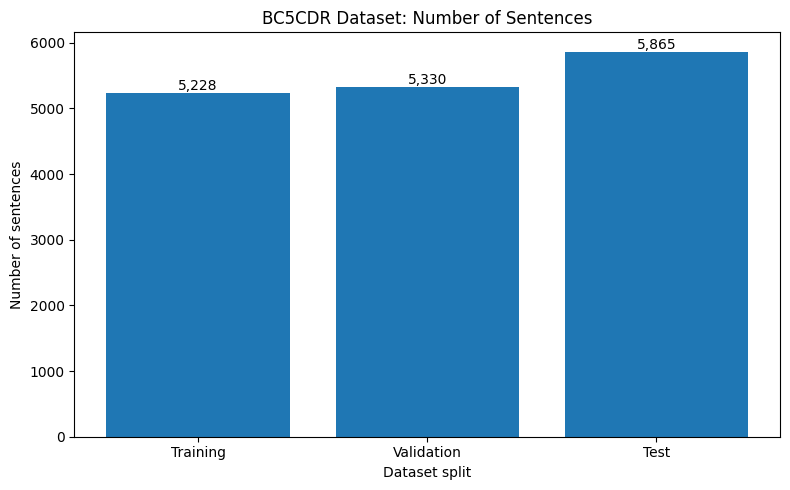

In [32]:
import matplotlib.pyplot as plt
split_names = ["Training", "Validation", "Test"]

split_counts = [
    len(train_data),
    len(valid_data),
    len(test_data)
]

plt.figure(figsize=(8, 5))
bars = plt.bar(split_names, split_counts)

plt.title("BC5CDR Dataset: Number of Sentences")
plt.xlabel("Dataset split")
plt.ylabel("Number of sentences")

for bar, count in zip(bars, split_counts):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{count:,}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.savefig(GRAPH_DIR / "01_dataset_splits.png", dpi=300)
plt.show()

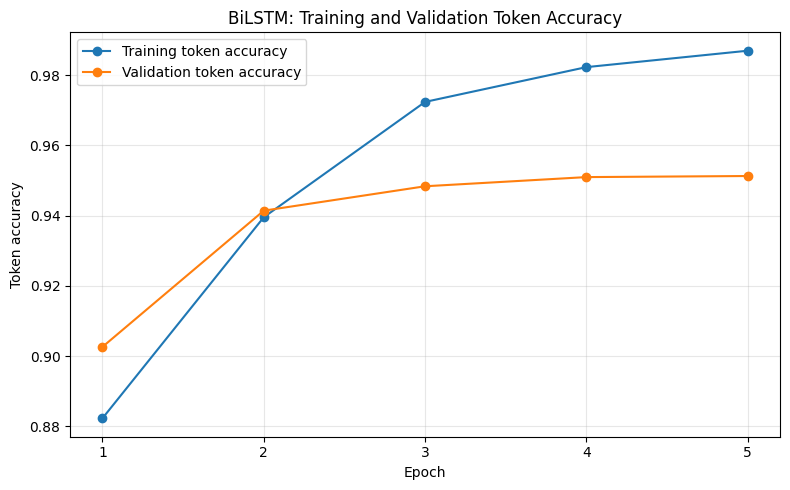

In [33]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["token_accuracy"],
    marker="o",
    label="Training token accuracy"
)

plt.plot(
    history.history["val_token_accuracy"],
    marker="o",
    label="Validation token accuracy"
)

plt.title("BiLSTM: Training and Validation Token Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Token accuracy")
plt.xticks(
    range(len(history.history["token_accuracy"])),
    range(1, len(history.history["token_accuracy"]) + 1)
)

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(GRAPH_DIR / "05_bilstm_token_accuracy.png", dpi=300)
plt.show()

In [34]:
def calculate_test_loss(model, data_loader):
    model.eval()
    total_loss = 0.0
    total_batches = 0

    with torch.no_grad():
        for batch in data_loader:
            ids = batch["input_ids"].to(DEVICE)
            mask = batch["attention_mask"].to(DEVICE)
            labels = batch["labels"].to(DEVICE)

            outputs = model(
                input_ids=ids,
                attention_mask=mask,
                labels=labels
            )

            total_loss += outputs.loss.item()
            total_batches += 1

    average_loss = total_loss / total_batches
    print(f"Test loss: {average_loss:.4f}")
    return average_loss


print("Frozen BioBERT")
calculate_test_loss(frozen_model, test_bert_loader)

print("\nFine-tuned BioBERT")
calculate_test_loss(finetuned_model, test_bert_loader)


Frozen BioBERT
Test loss: 0.1001

Fine-tuned BioBERT
Test loss: 0.0798


0.07976336990461218

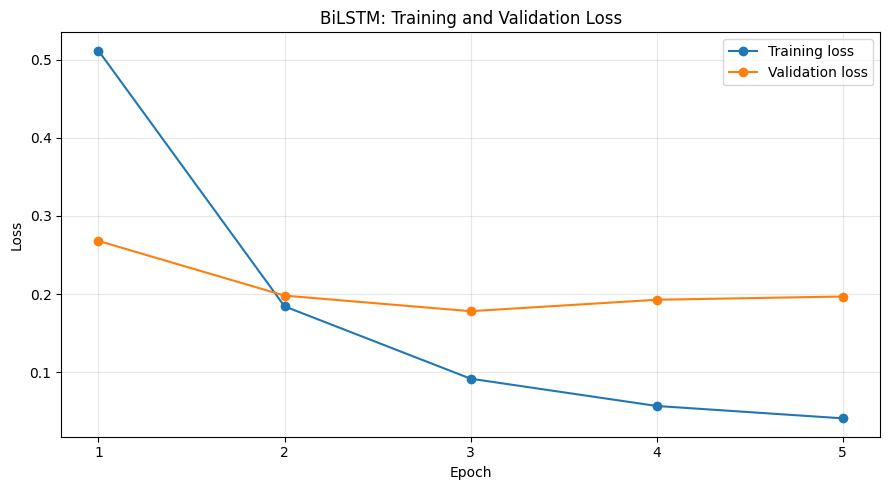

Graph saved: bc5cdr_dataset/graphs/04_bilstm_training_validation_loss.png


In [35]:

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    history.history["loss"],
    marker="o",
    label="Training loss"
)

plt.plot(
    history.history["val_loss"],
    marker="o",
    label="Validation loss"
)

plt.title("BiLSTM: Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(
    range(len(history.history["loss"])),
    range(1, len(history.history["loss"]) + 1)
)

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    GRAPH_DIR / "04_bilstm_training_validation_loss.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Graph saved:", GRAPH_DIR / "04_bilstm_training_validation_loss.png")
